
--- Clustering Evaluation Metrics across K ---
 Clusters (K)  Inertia (WCSS)  Silhouette Score
            2        70202.55            0.4129
            3        49034.19            0.3265
            4        42073.95            0.2484
            5        38659.04            0.1926
            6        36766.03            0.1544
            7        35134.43            0.1501
            8        33859.18            0.1432

--- Optimal KMeans Cluster Interpretation (K=3) ---
 cluster  Avg_Cycle    Avg_RUL  Engine_Records             Operational State
       2  68.048972 155.971848            7637              Stage 1: Healthy
       0 107.816670 103.861484            9082        Stage 2: Moderate Wear
       1 190.678425  22.944018            3912 Stage 3: Critical Degradation

Experiment 11 Completed Successfully


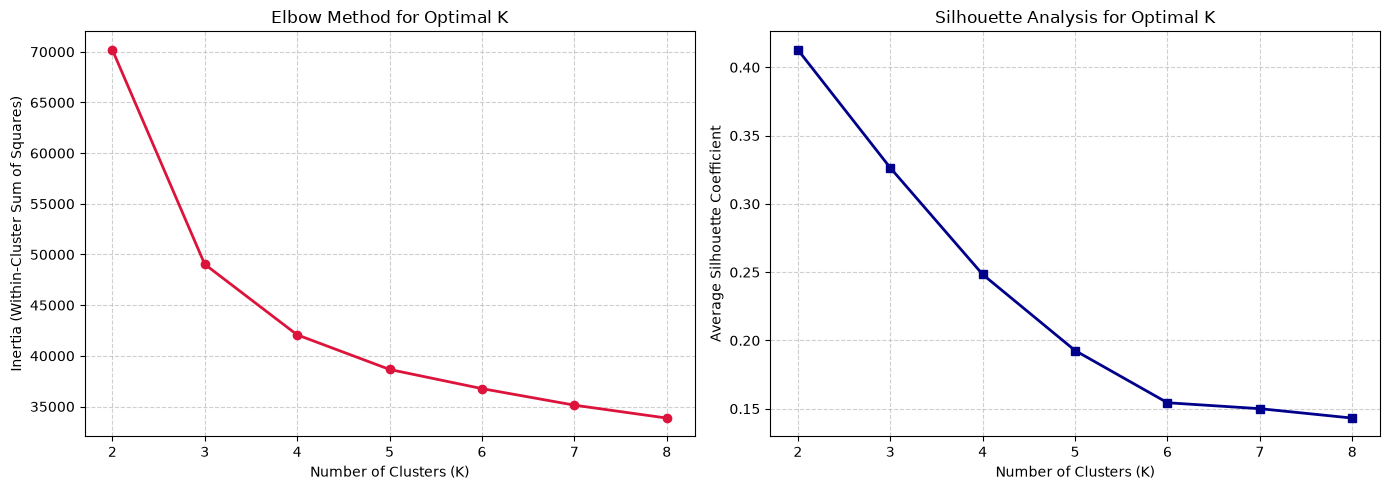

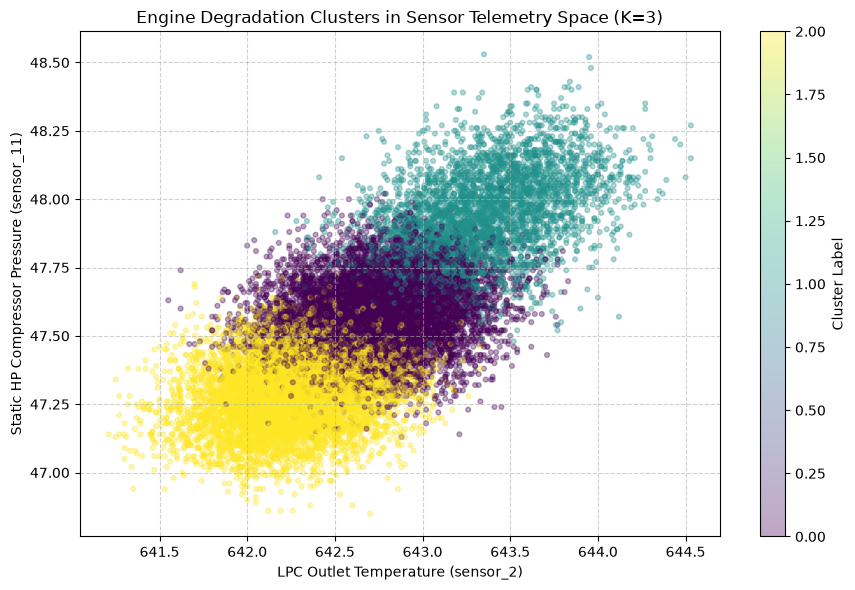

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


# Load C-MAPSS telemetry dataset
cols = ["engine_id", "cycle", "setting_1", "setting_2", "setting_3"] + [f"sensor_{i}" for i in range(1, 22)]
df = pd.read_csv("../dataset/CMAPSSData/train_FD001.txt", sep=r"\s+", header=None, names=cols)

df["RUL"] = df.groupby("engine_id")["cycle"].transform("max") - df["cycle"]

# Select high-sensitivity degradation sensors
cluster_features = ["sensor_2", "sensor_3", "sensor_4", "sensor_7", 
                    "sensor_11", "sensor_12", "sensor_15"]
X = df[cluster_features]

# Standardize feature scales for distance-based clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 1. Elbow Method (Inertia) & Silhouette Score across K
k_range = range(2, 9)
inertias = []
silhouette_scores = []

# Subsample for efficient silhouette computation
np.random.seed(42)
sample_idx = np.random.choice(len(X_scaled), size=3000, replace=False)
X_sample = X_scaled[sample_idx]

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)
    
    sil_score = silhouette_score(X_sample, kmeans.predict(X_sample))
    silhouette_scores.append(sil_score)

cluster_metrics = pd.DataFrame({
    "Clusters (K)": list(k_range),
    "Inertia (WCSS)": np.round(inertias, 2),
    "Silhouette Score": np.round(silhouette_scores, 4)
})
print("\n--- Clustering Evaluation Metrics across K ---")
print(cluster_metrics.to_string(index=False))

# 2. Plot Elbow Curve and Silhouette Scores
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow Curve
axes[0].plot(list(k_range), inertias, marker='o', color='crimson', lw=2)
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia (Within-Cluster Sum of Squares)")
axes[0].set_title("Elbow Method for Optimal K")
axes[0].set_xticks(list(k_range))
axes[0].grid(True, linestyle="--", alpha=0.6)

# Silhouette Curve
axes[1].plot(list(k_range), silhouette_scores, marker='s', color='darkblue', lw=2)
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Average Silhouette Coefficient")
axes[1].set_title("Silhouette Analysis for Optimal K")
axes[1].set_xticks(list(k_range))
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.show()

# 3. Fit Optimal KMeans (K=3 represents: Healthy, Degrading, Near-Failure)
optimal_k = 3
final_kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df["cluster"] = final_kmeans.fit_predict(X_scaled)

# Inspect cluster profiles relative to engine operating cycle and remaining life
cluster_summary = df.groupby("cluster").agg(
    Avg_Cycle=("cycle", "mean"),
    Avg_RUL=("RUL", "mean"),
    Engine_Records=("cycle", "count")
).reset_index()

# Map cluster IDs ordered by severity (Healthy -> Degrading -> Near Failure)
cluster_summary = cluster_summary.sort_values(by="Avg_RUL", ascending=False).reset_index(drop=True)
stage_labels = ["Stage 1: Healthy", "Stage 2: Moderate Wear", "Stage 3: Critical Degradation"]
cluster_summary["Operational State"] = stage_labels

print(f"\n--- Optimal KMeans Cluster Interpretation (K={optimal_k}) ---")
print(cluster_summary.to_string(index=False))

# 4. Cluster Scatter Plot in Core Sensor Telemetry Space
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    df["sensor_2"], df["sensor_11"],
    c=df["cluster"], cmap="viridis", alpha=0.35, s=12
)
plt.colorbar(scatter, label="Cluster Label")
plt.xlabel("LPC Outlet Temperature (sensor_2)")
plt.ylabel("Static Static HP Compressor Pressure (sensor_11)")
plt.title(f"Engine Degradation Clusters in Sensor Telemetry Space (K={optimal_k})")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

print("Experiment 11 Completed Successfully")